## Introduction

The project brief asks whether domain adaptation can improve generalisation. BioBERT and PubMedBERT beat plain BERT on NCBI Disease, but each was pre-trained on billions of words of biomedical text. This part tests a much cheaper form of domain adaptation, domain-adaptive pre-training (DAPT; Gururangan et al., 2020). We continue the masked-language-model (MLM) training of `bert-base-cased` on unlabelled PubMed abstracts and then fine-tune it for disease NER with exactly the same protocol, data and seeds as the BERT baseline. Only the starting weights change, so any difference in NER scores can be attributed to the extra pre-training.

The part has four sections: setup, the DAPT method and corpus, the results (pre-training and NER), and a discussion of why DAPT did not help.

## Setup

This section finds the repository root (or clones it on Colab), loads the plotting and table libraries, and defines a small helper that prints selected functions from the repository's code, so the key DAPT code can be shown without re-running training. All results below are read from files saved by the training runs in `dapt/results/`.

In [1]:
import os, sys, json, glob
from pathlib import Path
from collections import Counter

# Work from the repository root whether the notebook is opened from parts/ or from the root.
IN_COLAB = "google.colab" in sys.modules
if not Path("ner").exists() and Path("../ner").exists():
    os.chdir("..")
# On Colab, fetch the repository and the pinned library versions used for the runs.
if IN_COLAB and not Path("ner").exists():
    !git clone -b final-submission https://github.com/lofty14/bert-ner-baseline.git
    %cd bert-ner-baseline
    !pip -q install transformers==5.22.0 accelerate==1.15.0 seqeval==1.2.2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(".").resolve()
sys.path.insert(0, str(ROOT))          # make the shared ner/ package importable
pd.set_option("display.precision", 2)
print("repo root:", ROOT)

repo root: .../group_project


In [2]:
import ast

def show_source(path, names):
    """Print the source of selected top-level functions/classes without importing the module."""
    text = Path(path).read_text()
    tree = ast.parse(text)                 # parse only; nothing in the module is executed
    lines = text.splitlines()
    for node in tree.body:
        if getattr(node, "name", None) in names:
            # lineno / end_lineno give the exact line range of the definition
            print("\n".join(lines[node.lineno - 1:node.end_lineno]))
            print()

## Methods

DAPT has two stages: continued MLM pre-training of `bert-base-cased` on a disease-focused PubMed corpus, then ordinary NER fine-tuning. The corpus, the leakage check, the training settings and the evaluation are described below.

The corpus is 30,000 English PubMed abstracts from the MeSH *Diseases* category, sampled evenly across publication years (query and PMID list in `dapt/results/corpus_audit.json`); 115 records had no abstract.

NCBI Disease is itself built from PubMed abstracts, so the corpus was checked for leakage in two passes before training: by PMID (2 documents removed, both from the NCBI training split) and by sentence text against the NCBI dev and test sentences (none removed). No dev or test text was seen during pre-training.

Of the remaining abstracts, 29,257 (about 5.9 M words, 9.8 M word pieces) were used for training and 626 were held out to measure MLM perplexity. The split is a fixed hash of the PMID, so it is reproducible.

MLM training used non-overlapping 256-token windows, dynamic masking of 15% of tokens, batch size 32 and learning rate 5e-5 with 6% linear warm-up. We kept two checkpoints: 1 epoch (1,632 steps, 0.8 h) and 3 epochs (4,896 steps, 2.2 h) on an Apple M-series GPU.

Each checkpoint was then fine-tuned with the unified protocol (learning rate 2e-5, batch size 8, 3 epochs, epoch selected on dev strict F1) for seeds 1, 2 and 3, and scored with seqeval strict entity-level precision, recall and F1 (IOB2) on the test set. The BERT baseline in the tables below was re-run under the same protocol and seeds, so the comparison is paired by seed.

The cell below prints the windowing and masking code and the recorded training statistics.

In [3]:
# Show the two pieces of code that define DAPT's input: windowing and masking.
show_source("ner/dapt.py", ["make_windows", "MLMCollator"])

# Statistics recorded by the 3-epoch DAPT run.
d = json.load(open("dapt/results/bert_dapt_3ep.dapt.json"))
print("corpus:", d["corpus"]["documents"], "documents,", f'{d["corpus"]["train_tokens"]:,}', "training tokens")
print("MLM config:", {k: d["config"][k] for k in ["epochs", "batch_size", "lr", "max_length", "mlm_probability"]})
# Perplexity on the 626 held-out abstracts, before and after continued pre-training
print("validation perplexity: %.2f -> %.2f" % (d["valid_perplexity"]["initial"], d["valid_perplexity"]["final"]))
print("training time: %.1f h" % (d["seconds"]["total"] / 3600))

def make_windows(texts, tokenizer, max_length):
    """Non-overlapping [CLS] + pieces + [SEP] windows of at most max_length tokens."""
    size = max_length - 2
    features = []
    for start in range(0, len(texts), 1000):
        ids = tokenizer(texts[start:start + 1000], add_special_tokens=False, truncation=False,
                        verbose=False)["input_ids"]
        for doc in ids:
            for i in range(0, len(doc), size):
                piece = [tokenizer.cls_token_id] + doc[i:i + size] + [tokenizer.sep_token_id]
                features.append({"input_ids": piece,
                                 "special_tokens_mask": [1] + [0] * (len(piece) - 2) + [1]})
    return features

class MLMCollator:
    """Dynamic masking for training windows; windows that already carry labels are only padded."""

    def __init__(self, tokenizer, mlm_probability):
        self.mlm = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm_probability=mlm_probability)
        self.pad_id =

## Results

We first check that the continued pre-training worked, using the MLM loss on the held-out abstracts, and then compare NER scores with and without DAPT over the same three seeds.

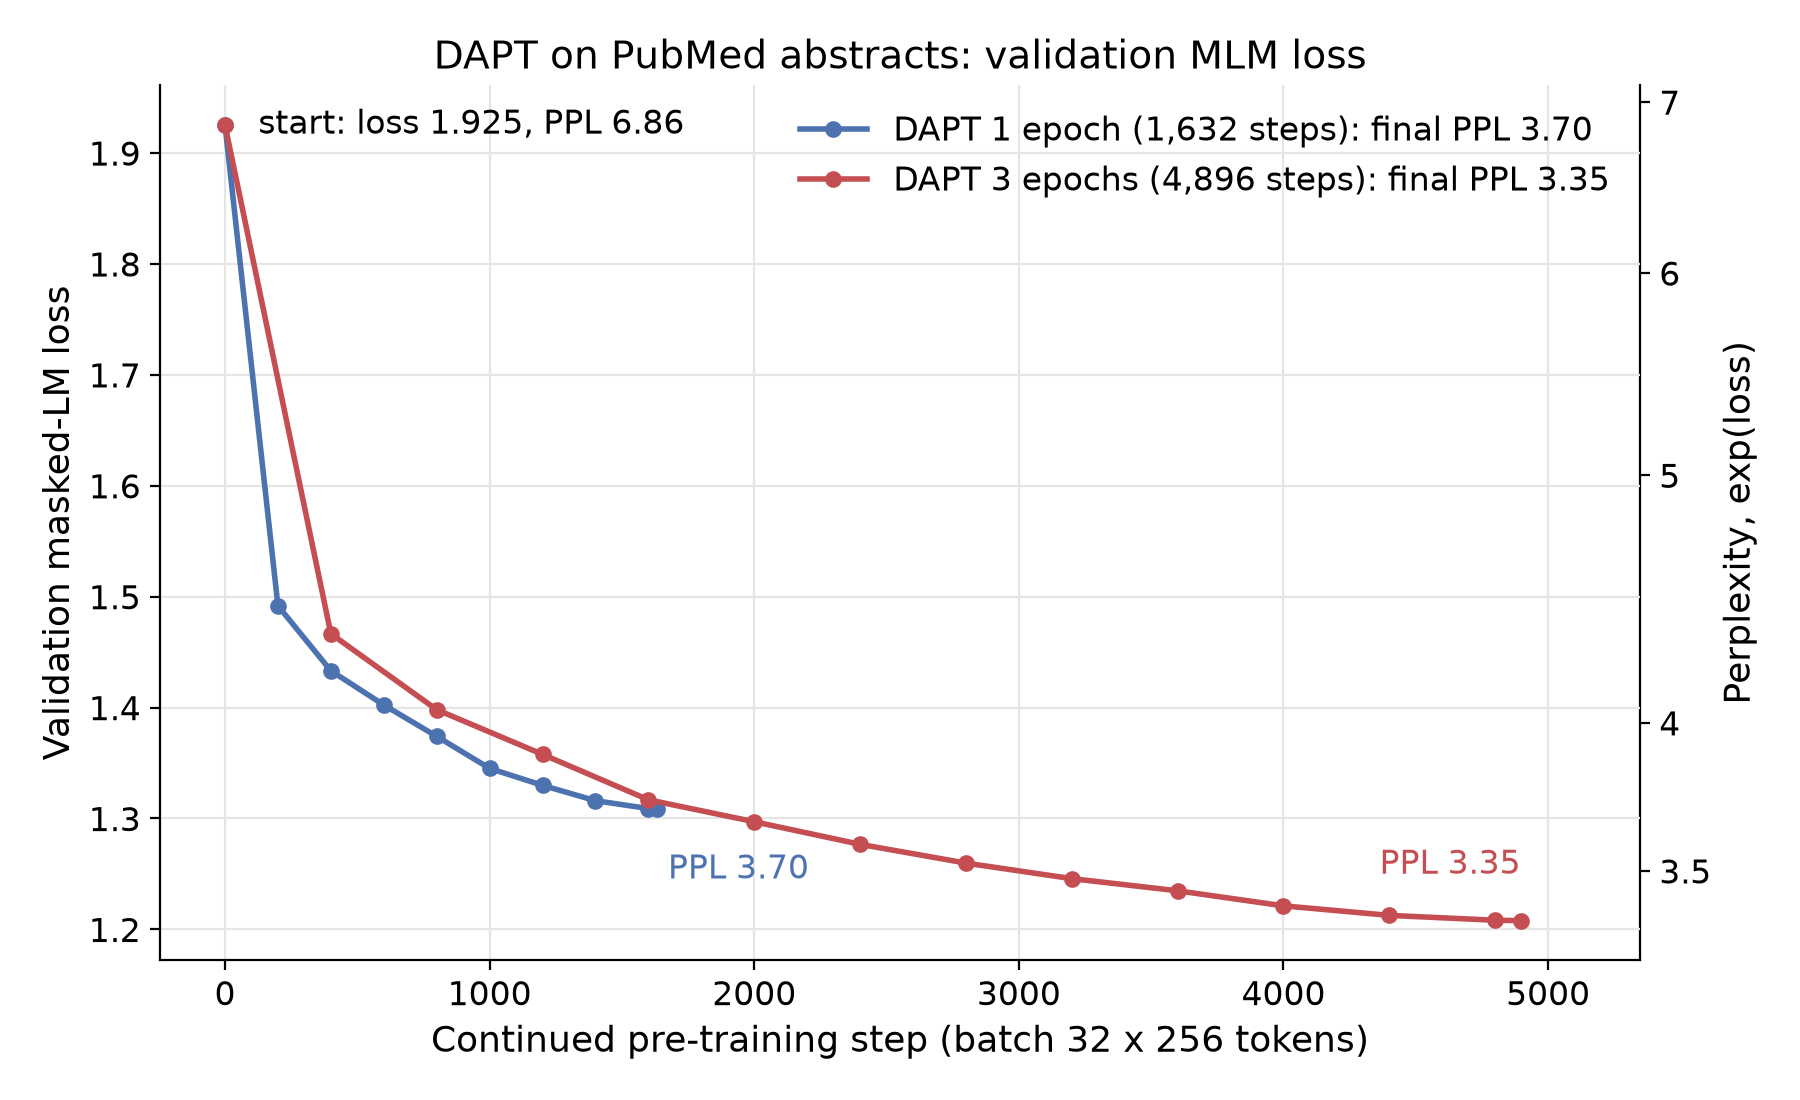

In [4]:
from IPython.display import Image, display

# Validation MLM loss during continued pre-training (saved by dapt/plot_dapt.py).
display(Image("dapt/figs/mlm_valid_loss.png", width=600))

The pre-training worked as intended. Perplexity on the 626 held-out abstracts fell from 6.86 for the original BERT to 3.70 after 1 epoch and 3.35 after 3 epochs, and the validation loss was still decreasing slowly at the end (plot above). The model clearly learned to predict biomedical text better; the question is whether that helps NER.

The next three cells give the NER scores: the summary table over seeds, the per-seed test F1, and the paired comparison of the 3-epoch model against BERT.

In [5]:
# Summary table: mean ± std over seeds 1-3 for BERT and both DAPT checkpoints
# (the model-selection details after this heading are omitted).
print(Path("dapt/results/results.md").read_text().split("#### model selection")[0])

Scores are percentages, mean ± sample std over seeds. `default` = seqeval default mode, `strict` = mode='strict', scheme=IOB2.

### precision: fp32; dev selection metric: strict_f1

#### dev (selected epoch)

| model | n seeds | P (default) | R (default) | F1 (default) | P (strict) | R (strict) | F1 (strict) | token acc |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| bert | 3 (1,2,3) | 81.17 ± 0.37 | 87.25 ± 0.48 | 84.10 ± 0.40 | 83.60 ± 0.90 | 87.00 ± 0.48 | 85.26 ± 0.56 | 98.63 ± 0.05 |
| bert+dapt1ep | 3 (1,2,3) | 80.17 ± 0.47 | 86.79 ± 0.13 | 83.34 ± 0.21 | 82.06 ± 0.76 | 86.57 ± 0.07 | 84.26 ± 0.36 | 98.59 ± 0.04 |
| bert+dapt3ep | 3 (1,2,3) | 80.19 ± 0.62 | 86.91 ± 0.22 | 83.42 ± 0.26 | 82.13 ± 0.84 | 86.79 ± 0.22 | 84.39 ± 0.38 | 98.60 ± 0.04 |

#### test, dev-selected epoch

| model | n seeds | P (default) | R (default) | F1 (default) | P (strict) | R (strict) | F1 (strict) | token acc |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| bert | 3 (1,2,3) | 81.57 ± 0.11 | 87.29 ±

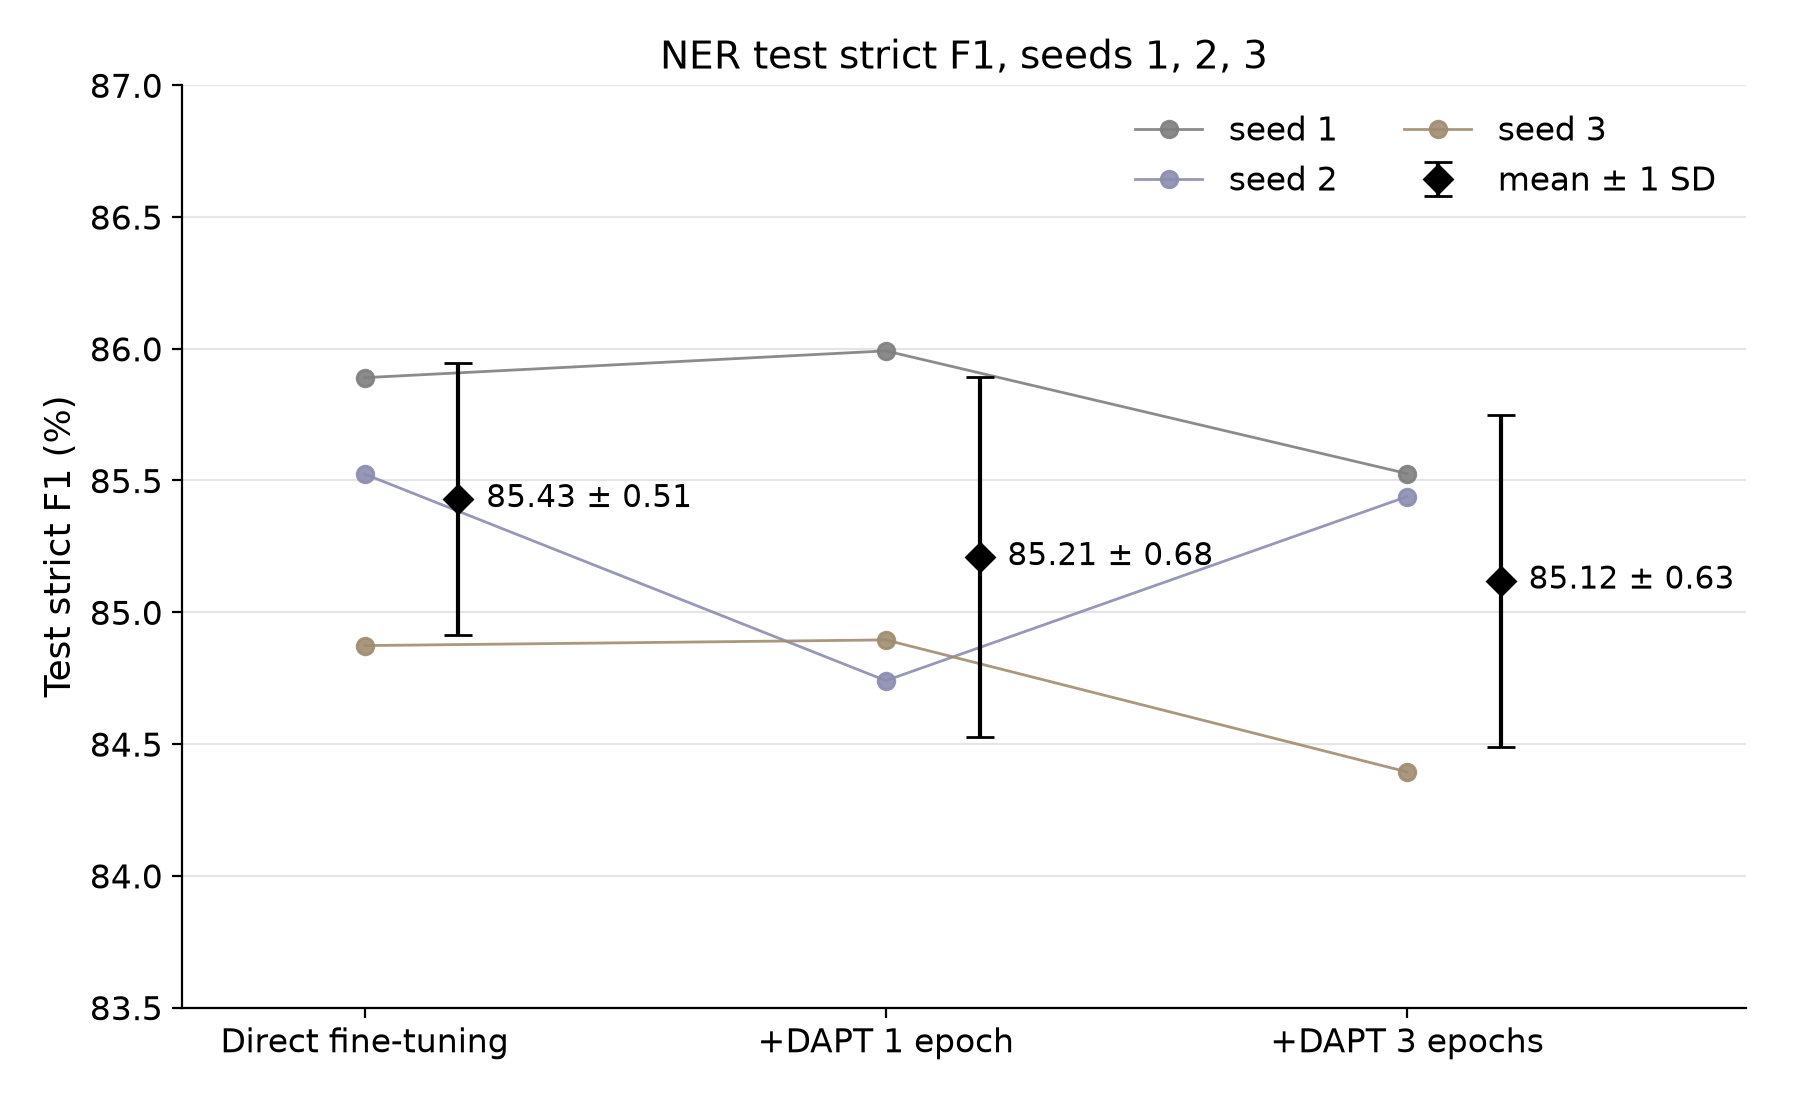

In [6]:
# Test strict F1 per seed; lines join the same seed across models.
display(Image("dapt/figs/ner_f1_paired.png", width=650))

In [7]:
# Paired differences (DAPT 3 epochs minus BERT) for each seed, on dev and test.
print(Path("dapt/results/compare_dapt3ep.md").read_text()[:4000])

Paired comparison `bert+dapt3ep` − `bert` over seeds 1, 2, 3 (precision fp32, dev selection strict_f1). Scores are percentages, seqeval strict IOB2 entity level; Δ = b − a.

#### dev (selected epoch)

| seed | bert P | bert R | bert F1 | bert+dapt3ep P | bert+dapt3ep R | bert+dapt3ep F1 | ΔP | ΔR | ΔF1 |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 1 | 82.59 | 86.79 | 84.63 | 81.45 | 87.04 | 84.15 | -1.14 | +0.25 | -0.48 |
| 2 | 83.92 | 87.55 | 85.70 | 81.87 | 86.66 | 84.20 | -2.05 | -0.89 | -1.50 |
| 3 | 84.30 | 86.66 | 85.46 | 83.07 | 86.66 | 84.83 | -1.23 | +0.00 | -0.64 |
| mean ± std |  |  |  |  |  |  | -1.47 ± 0.50 | -0.21 ± 0.60 | -0.87 ± 0.55 |
| seeds Δ > 0 |  |  |  |  |  |  | 0/3 | 1/3 | 0/3 |

#### test, dev-selected epoch

| seed | bert P | bert R | bert F1 | bert+dapt3ep P | bert+dapt3ep R | bert+dapt3ep F1 | ΔP | ΔR | ΔF1 |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 1 | 84.63 | 87.19 | 85.89 | 83.17 | 88.02 | 85.53 | -1.46 | +0.83 | -0.36 |
| 2 | 84.02

## Discussion

In short, DAPT lowered perplexity but did not improve NER. This section looks at the size of the effect, where the errors changed, why the gain did not appear, and what we take from it.

On the test set, strict F1 was 85.43 ± 0.51 for BERT, 85.21 ± 0.68 after 1 epoch of DAPT and 85.12 ± 0.63 after 3 epochs. Paired by seed, the 3-epoch model changed F1 by −0.31 ± 0.20 points and was slightly lower in all three seeds; on the dev set the drop was −0.87 ± 0.55. Each drop is smaller than the spread between seeds of the same model, so the result is best read as no gain, possibly a small loss, and certainly not the 1.5–2 point gain that BioBERT and PubMedBERT show over BERT.

DAPT raised test recall (+0.49 ± 0.43 for 3 epochs) but lowered precision (−1.04 ± 0.37, all three seeds). The entity-level error analysis (`dapt/results/error_analysis_dapt3ep.md`, pooled over seeds) shows where this comes from: the DAPT model found 14 more gold entities but produced 40 more false positives, 25 of them spurious (no overlap with any gold mention) and 15 with wrong boundaries. Typical new errors are biomedical words that are not disease mentions in this annotation scheme: the twin-study abbreviations *DZ* and *MZ* (dizygotic / monozygotic), the gene name *APC* next to the disease *FAP*, and generic words such as *deficiency* or *congenital* on their own. Our reading is that the MLM stage made the model more sensitive to biomedical vocabulary in general, which helps it notice more mentions but also makes it tag terms that look disease-like.

The main reason for the missing gain is scale. Our corpus is about 10 M word pieces and 3 epochs, while BioBERT was trained on about 18 B words of PubMed and PMC and PubMedBERT on about 3 B words from scratch with an in-domain vocabulary. DAPT also keeps BERT's general WordPiece vocabulary, so disease names are still split into many pieces. With labelled data this small (about 5,000 training sentences), fine-tuning already adapts BERT to the task, and the extra pre-training at this scale is not enough to change what the classifier learns.

We draw three conclusions. First, a cheap DAPT run is not a substitute for a biomedical pre-trained model: for this task, starting from BioBERT or PubMedBERT is more effective than adapting BERT ourselves. Second, lower perplexity did not translate into better NER, so MLM loss alone is not a good proxy for downstream gains. Third, the next steps would be a much larger corpus with longer training, task-adaptive pre-training on unlabelled text close to the NCBI abstracts, or applying DAPT on top of BioBERT rather than plain BERT; more seeds would also be needed to detect differences below half a point.